# Credit Default Scoring
Полное обучение: `python -m creditrisk.pipeline` (~6 мин). Ноутбук показывает данные, признаки, скоркарту и итоговые результаты из `reports/metrics.json`.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
from creditrisk.data import load_features
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)
m = json.load(open('../reports/metrics.json', encoding='utf-8'))

## 1. Данные и признаки (SQL в DuckDB)

In [2]:
df = load_features('../data/raw/credit_default.csv')
print(df.shape, 'доля дефолтов:', round(df.default.mean(), 3))
df.head()

(23976, 27) доля дефолтов: 0.221


,client_id,default,sex,marriage,education,age,limit_bal,pay_1,pay_2,pay_3,pay_4,pay_5,pay_6,max_delay,n_delay_months,n_paid_duly,n_no_use,delay_trend,util_1,util_avg,util_max,bill_change,n_overlimit,paid_to_limit,paid_1_to_limit,pay_ratio_avg,exposure
0,0,1,2,1,2,24,20000,2,2,-1,-1,-2,-2,2,2,2,2,2.666667,0.195650,0.064200,0.195650,0.195650,0,0.005742,0.000000,0.500000,1284.000000
1,1,0,2,2,2,34,90000,0,0,0,0,0,0,0,0,0,0,0.000000,0.324878,0.188246,0.324878,0.152111,0,0.020404,0.016867,0.083968,16942.166667
2,2,0,2,1,2,37,50000,0,0,0,0,0,0,0,0,0,0,0.000000,0.939800,0.771113,0.985820,0.348860,0,0.027960,0.040000,0.039794,38555.666667
3,3,0,1,1,2,57,50000,-1,0,-1,0,0,0,0,0,2,0,-0.666667,0.172340,0.364463,0.716700,-0.210280,0,0.196830,0.040000,0.471997,18223.166667
4,4,0,1,2,1,37,50000,0,0,0,0,0,0,0,0,0,0,0.000000,1.288000,0.793713,1.288000,0.887520,3,0.025907,0.050000,0.042020,39685.666667


## 2. EDA

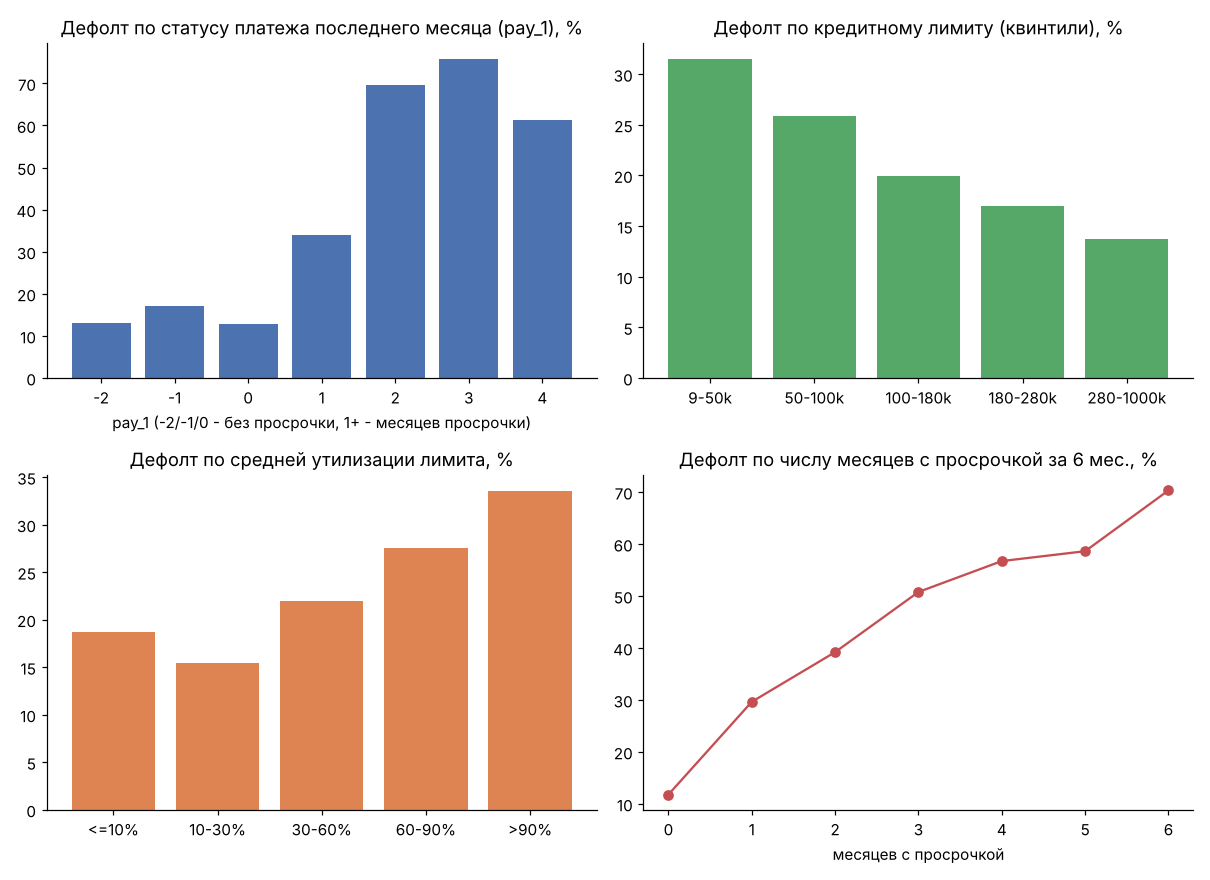

In [3]:
display(Image('../reports/figures/01_eda.png'))

## 3. Сравнение моделей (5-fold CV, OOF на train)

In [4]:
pd.DataFrame(m['cv']).round(4)

,model,cv_roc_auc,cv_auc_std,cv_gini,cv_ks,cv_pr_auc
0,LogReg,0.7532,0.0095,0.5063,0.4036,0.5067
1,Scorecard (WoE+LogReg),0.7633,0.0079,0.5267,0.4017,0.5290
2,RandomForest,0.7803,0.0079,0.5607,0.4264,0.5498
3,LightGBM,0.7804,0.0098,0.5609,0.4279,0.5525
4,LightGBM (tuned),0.7832,0.0077,0.5664,0.4333,0.5548


## 4. Hold-out: метрики, ROC/KS, децили

,roc_auc,gini,ks,pr_auc,brier,log_loss
LogReg,0.7602,0.5204,0.4207,0.5204,0.1391,0.4426
Scorecard,0.7761,0.5522,0.4204,0.5427,0.1356,0.4332
LightGBM_raw,0.7899,0.5798,0.4527,0.5687,0.1319,0.4219
LightGBM_calibrated,0.7908,0.5816,0.4524,0.5702,0.1317,0.4219


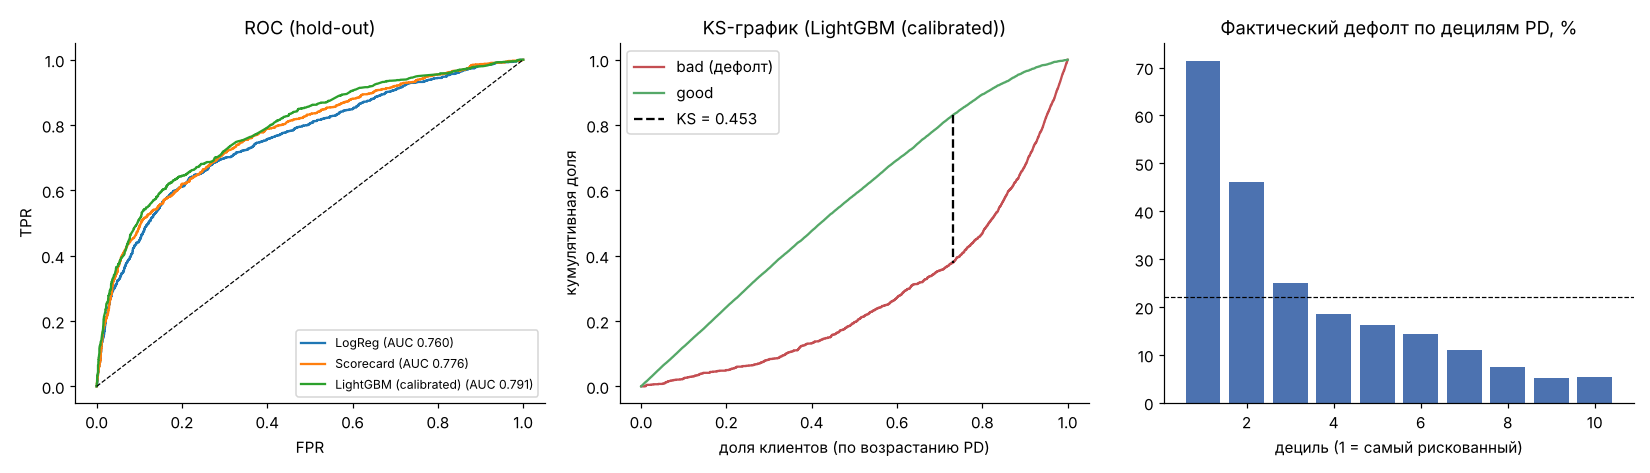

,decile,n,defaults,avg_pd,default_rate,lift,cum_capture
0,1,480,343,0.722,0.715,3.233,0.324
1,2,480,221,0.433,0.460,2.083,0.532
2,3,479,120,0.273,0.250,1.134,0.645
3,4,480,89,0.190,0.185,0.839,0.729
4,5,479,78,0.163,0.163,0.737,0.803
5,6,480,69,0.140,0.144,0.650,0.868
6,7,479,53,0.114,0.111,0.501,0.918
7,8,480,36,0.089,0.075,0.339,0.952
8,9,479,25,0.069,0.052,0.236,0.976
9,10,480,26,0.036,0.054,0.245,1.000


In [5]:
display(pd.DataFrame(m['holdout']).round(4).T)
display(Image('../reports/figures/02_model_quality.png'))
pd.DataFrame(m['decile_table']).round(3)

## 5. Калибровка и скоркарта
IV и баллы: чем выше балл, тем ниже риск. Базовые 600 баллов при шансах 50:1, PDO = 20.

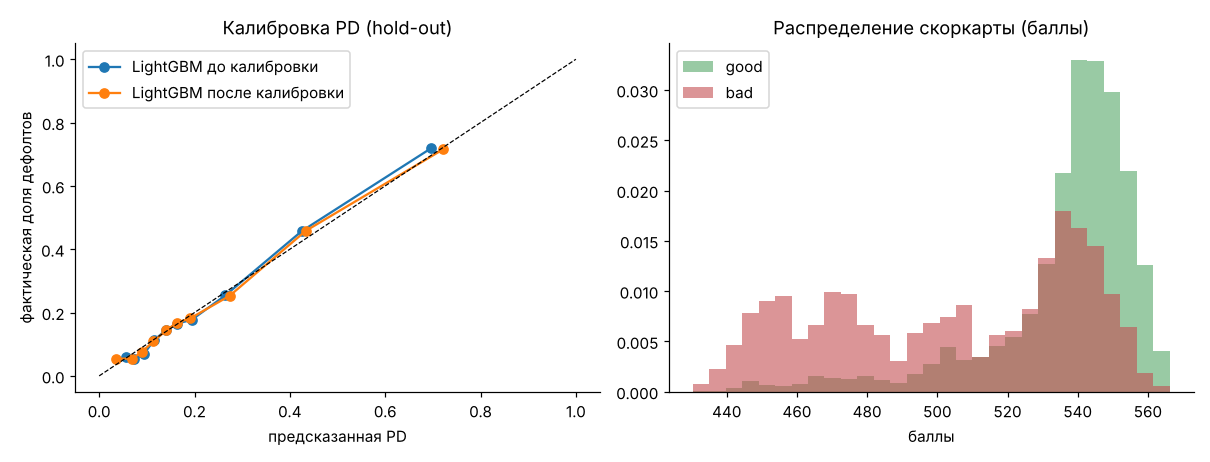

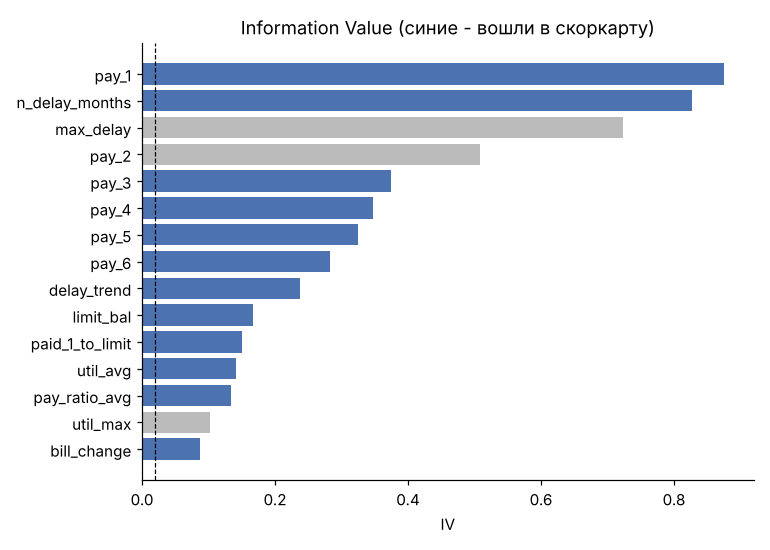

,feature,bin,n,bad_rate,woe,points,iv
0,pay_1,<= -1.5,1745,0.13,0.61,52.40,0.88
1,pay_1,"(-1.5, -0.5]",3686,0.17,0.31,46.39,0.88
2,pay_1,"(-0.5, 0.5]",9442,0.13,0.67,53.60,0.88
3,pay_1,"(0.5, 1.5]",2341,0.34,-0.60,28.27,0.88
4,pay_1,> 1.5,1966,0.70,-2.11,-1.78,0.88
31,limit_bal,<= 3e+04,2610,0.36,-0.68,32.27,0.17
32,limit_bal,"(3e+04, 5e+04]",2289,0.26,-0.23,37.58,0.17
33,limit_bal,"(5e+04, 9e+04]",2425,0.26,-0.23,37.52,0.17
34,limit_bal,"(9e+04, 1.4e+05]",2434,0.23,-0.03,39.83,0.17
35,limit_bal,"(1.4e+05, 1.9e+05]",2271,0.18,0.23,42.90,0.17


In [6]:
display(Image('../reports/figures/03_calibration_scores.png'))
display(Image('../reports/figures/05_information_value.png'))
sc = pd.read_csv('../reports/scorecard_table.csv')
sc[sc.feature.isin(['pay_1','limit_bal','util_avg'])].round(2)

## 6. SHAP

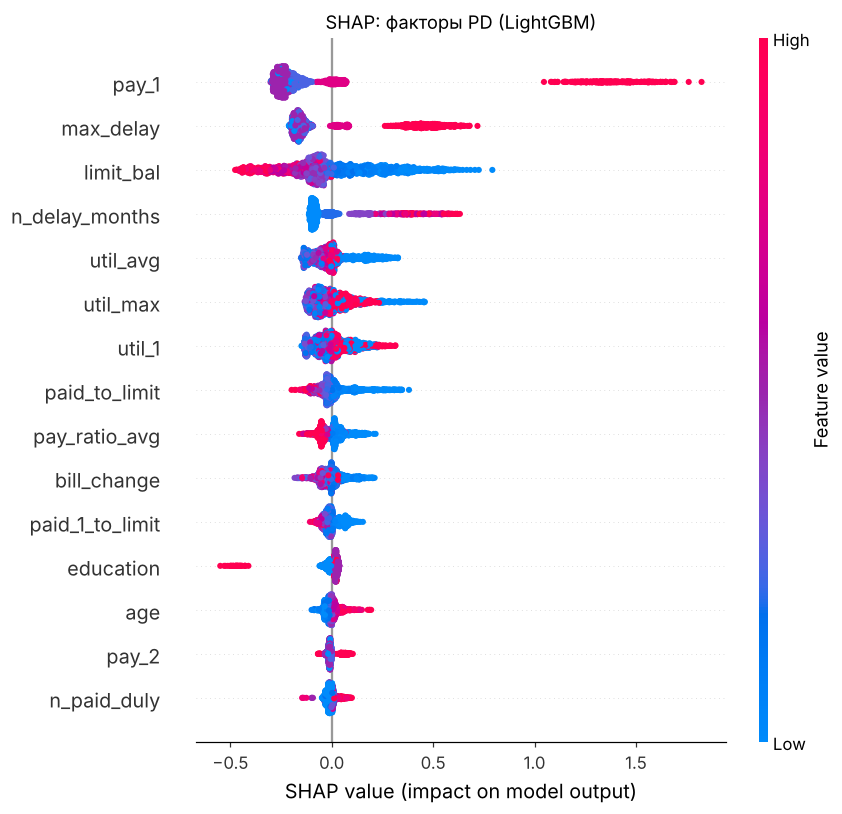

In [7]:
display(Image('../reports/figures/04_shap_summary.png'))

## 7. Бизнес: порог и стратегии (допущения r = 0.20, LGD = 0.60)

{'interest_rate': 0.2, 'lgd': 0.6} порог безубыточности: 0.25


,strategy,approval_rate,default_rate_approved,profit
0,Отказать всем,0.000,NaN,0.000000e+00
1,Одобрить всех,1.000,0.221,5.881211e+06
2,Правило: нет просрочки сейчас (pay_1 <= 0),0.777,0.139,1.784705e+07
3,"Скоркарта, PD < порога безубыточности",0.764,0.129,1.857021e+07
4,"LightGBM, PD < порога безубыточности",0.739,0.117,1.846682e+07
5,"LightGBM, порог по OOF-прибыли",0.765,0.123,1.840581e+07


бутстрэп, модель минус правило: {'profit_diff_model_vs_rule_mean': 608624.7141333332, 'ci95': [45921.18416666975, 1197908.9791666619], 'share_bootstrap_model_better': 0.985}


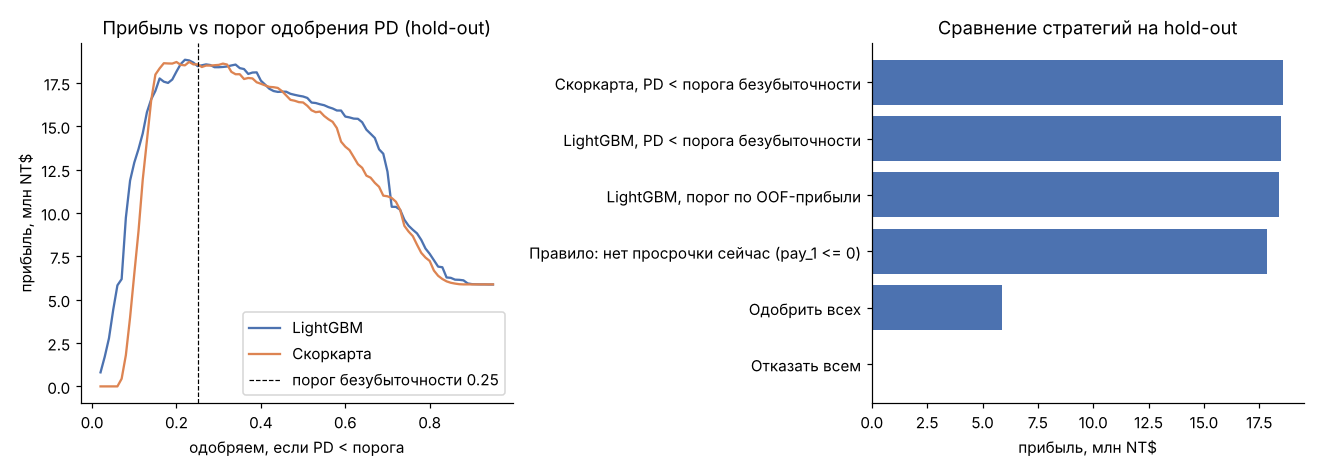

,interest_rate,lgd,breakeven_pd,profit_model,profit_rule,profit_approve_all,approval_rate_model
0,0.10,0.4,0.20,7442332.77,6971533.43,-1656563.12,0.68
1,0.10,0.6,0.14,6062351.30,3067554.20,-10850900.52,0.46
2,0.10,0.8,0.11,4192660.08,-836425.03,-20045237.92,0.34
3,0.15,0.4,0.27,14832272.54,14361279.38,6709492.72,0.76
4,0.15,0.6,0.20,11163499.15,10457300.15,-2484844.67,0.68
5,0.15,0.8,0.16,9566397.86,6553320.92,-11679182.08,0.54
6,0.20,0.4,0.33,22289349.97,21751025.33,15075548.57,0.79
7,0.20,0.6,0.25,18466815.80,17847046.10,5881211.17,0.74
8,0.20,0.8,0.20,14884665.53,13943066.87,-3313126.23,0.68
9,0.30,0.4,0.43,36922387.45,36530517.23,31807660.25,0.85


In [8]:
b = m['business']
print(b['assumptions'], 'порог безубыточности:', b['breakeven_pd'])
display(pd.DataFrame(b['strategies']).round(3))
print('бутстрэп, модель минус правило:', b['bootstrap_model_vs_rule'])
display(Image('../reports/figures/06_profit.png'))
pd.DataFrame(b['sensitivity']).round(2)

## 8. Справедливость

disparate impact: {'age': 0.8747967217433144, 'sex': 0.9503632632688148}


,attribute,group,n,approval_rate,approval_rate_among_good,default_rate_approved,mean_pd,actual_default_rate,auc
0,sex,female,2898,0.754,0.842,0.113,0.216,0.205,0.777
1,sex,male,1898,0.716,0.831,0.124,0.234,0.245,0.808
2,age,30-44,2393,0.771,0.859,0.108,0.209,0.199,0.788
3,age,45+,807,0.674,0.797,0.129,0.247,0.263,0.797
4,age,<30,1596,0.725,0.824,0.127,0.231,0.232,0.786


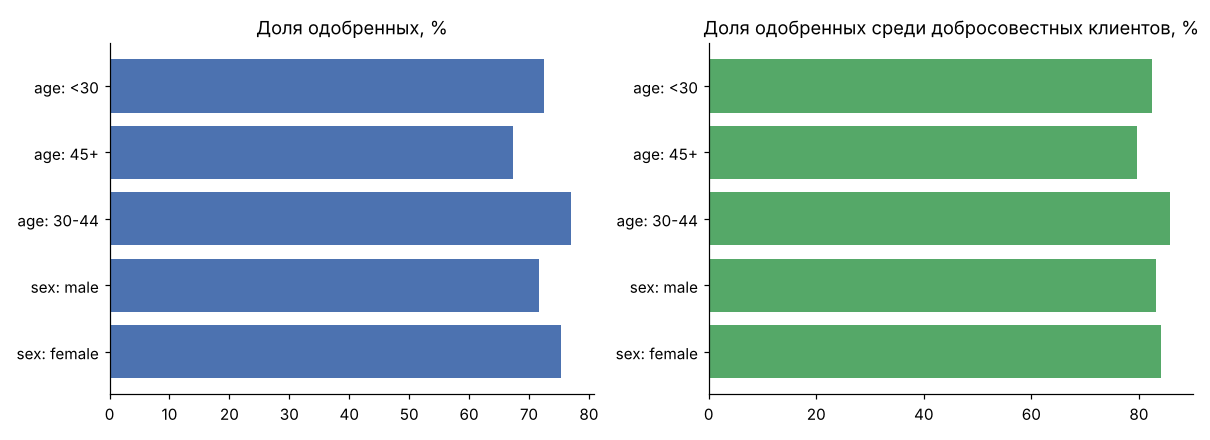

In [9]:
f = m['fairness']
print('disparate impact:', f['disparate_impact'])
display(pd.DataFrame(f['table']).round(3))
display(Image('../reports/figures/07_fairness.png'))

## 9. Скоринг новых клиентов (обученная модель)

In [10]:
from creditrisk.scoring import score_clients
raw = pd.read_csv('../data/raw/credit_default.csv').drop(columns=['default']).head(8)
score_clients(raw).round(3)

,client_id,limit_bal,pd,score,decision,decline_reasons
0,0,20000,0.581,476.086,decline,"pay_1, limit_bal, delay_trend"
1,1,90000,0.077,550.418,approve,
2,2,50000,0.158,539.026,approve,
3,3,50000,0.112,533.904,approve,
4,4,50000,0.162,539.068,approve,
5,5,100000,0.106,551.775,approve,
6,6,140000,0.178,544.945,approve,
7,7,20000,0.156,534.548,approve,
